# Australian Rainfall Prediction using Machine Learning

This project predicts rainfall for the Melbourne area using reproducible scikit-learn pipelines. It began as the IBM *Machine Learning with Python* final project and was expanded into a portfolio-ready analysis.

**Executed result:** `Random Forest (tuned)` was selected by the strongest mean cross-validated ROC-AUC, without using the held-out test set for model selection. On the test set it achieved **0.841 accuracy**, **0.492 recall**, **0.595 F1**, and **0.885 ROC-AUC**.

> All metrics and figures in this notebook are generated from `weatherAUS_2.csv`; no values are fabricated.

## 1. Project Overview

The binary target is whether it rains on the current conceptual day. The original dataset's `RainTomorrow` is renamed `RainToday`, while original same-row weather measurements represent the preceding day. This preserves the IBM exercise's practical forecasting frame.

## 2. Dataset

The file is the local `weatherAUS_2.csv`. The IBM notebook attributes the underlying observations to Australia's Bureau of Meteorology and the packaged dataset to Kaggle's *Rain in Australia* dataset. The analysis retains complete cases from Melbourne, Melbourne Airport, and Watsonia, matching the course workflow.

## 3. Imports and Configuration

In [1]:
from pathlib import Path
import json
import joblib
import os
os.environ.setdefault("MPLCONFIGDIR", ".matplotlib")
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, precision_score,
                             recall_score, roc_auc_score, RocCurveDisplay)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
DATA_PATH = Path("weatherAUS_2.csv")
LOCATIONS = ["Melbourne", "MelbourneAirport", "Watsonia"]
IMAGES_DIR = Path("images")
MODELS_DIR = Path("models")
RESULTS_DIR = Path("results")
for directory in (IMAGES_DIR, MODELS_DIR, RESULTS_DIR):
    directory.mkdir(exist_ok=True)

plt.rcParams.update({"figure.figsize": (8, 5), "axes.grid": True, "grid.alpha": 0.18,
                     "axes.titleweight": "bold", "font.size": 10})

## 4. Data Loading

In [2]:
raw_df = pd.read_csv(DATA_PATH)
print(f"Raw shape: {raw_df.shape[0]:,} rows x {raw_df.shape[1]} columns")
raw_df.head(3)

Raw shape: 145,460 rows x 23 columns


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No


## 5. Data Understanding

In [3]:
data_summary = pd.DataFrame({
    "dtype": raw_df.dtypes.astype(str),
    "missing": raw_df.isna().sum(),
    "unique": raw_df.nunique(dropna=True),
})
display(data_summary)
print("Duplicate rows:", raw_df.duplicated().sum())
print("Raw target values:", raw_df["RainTomorrow"].value_counts(dropna=False).to_dict())

,dtype,missing,unique
Date,str,0,3436
Location,str,0,49
MinTemp,float64,1485,389
MaxTemp,float64,1261,505
Rainfall,float64,3261,681
Evaporation,float64,62790,358
Sunshine,float64,69835,145
WindGustDir,str,10326,16
WindGustSpeed,float64,10263,67
WindDir9am,str,10566,16


Duplicate rows: 0
Raw target values: {'No': 110316, 'Yes': 31877, nan: 3267}


## 6. Data Cleaning

To remain faithful to the IBM exercise, rows with any missing values are removed before restricting the geography. This complete-case choice reduces the available sample and may introduce selection bias; an imputer-based alternative is a reasonable future extension.

In [4]:
complete_df = raw_df.dropna().copy()
df = complete_df.loc[complete_df["Location"].isin(LOCATIONS)].copy()
print(f"Complete rows across Australia: {len(complete_df):,}")
print(f"Complete rows in selected locations: {len(df):,}")
df["Location"].value_counts()

Complete rows across Australia: 56,420
Complete rows in selected locations: 7,557


Location
MelbourneAirport    2929
Watsonia            2730
Melbourne           1898
Name: count, dtype: int64

## 7. Data Leakage Considerations

Several measurements—such as rainfall, afternoon humidity, and cloud cover—are only known after the original observation day has progressed. Using them to predict that same original day's `RainToday` would leak information. Following the IBM notebook, the target is shifted conceptually by renaming original `RainTomorrow` to `RainToday` and original `RainToday` to `RainYesterday`. All remaining weather predictors are therefore interpreted as prior-day information relative to the target. Preprocessing is fitted inside each pipeline and only on training folds.

In [5]:
df = df.rename(columns={"RainToday": "RainYesterday", "RainTomorrow": "RainToday"})
assert "RainTomorrow" not in df.columns
df[["RainYesterday", "RainToday"]].head()

,RainYesterday,RainToday
64191,No,Yes
64192,Yes,No
64193,No,No
64194,No,No
64195,No,No


## 8. Exploratory Data Analysis

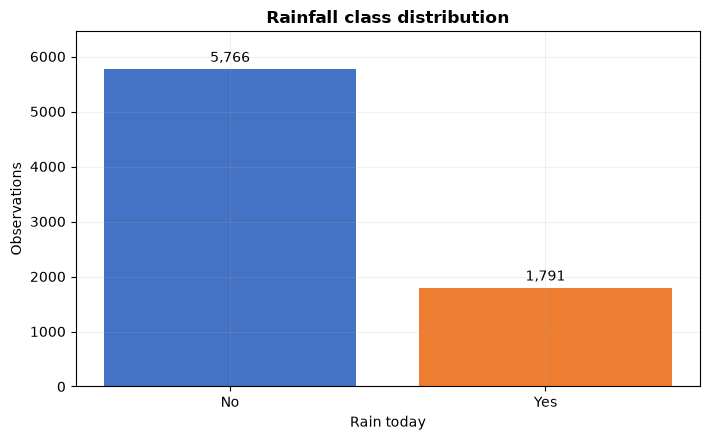

Rain occurs in 23.7% of retained observations.


In [6]:
counts = df["RainToday"].value_counts().reindex(["No", "Yes"])
fig, ax = plt.subplots(figsize=(7.2, 4.5))
bars = ax.bar(counts.index, counts.values, color=["#4472C4", "#ED7D31"])
ax.bar_label(bars, fmt="{:,.0f}", padding=3)
ax.set(title="Rainfall class distribution", xlabel="Rain today", ylabel="Observations")
ax.set_ylim(0, counts.max() * 1.12)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "class_distribution.png", dpi=180, bbox_inches="tight")
plt.show()
print(f"Rain occurs in {(df['RainToday'] == 'Yes').mean():.1%} of retained observations.")

## 9. Feature Engineering

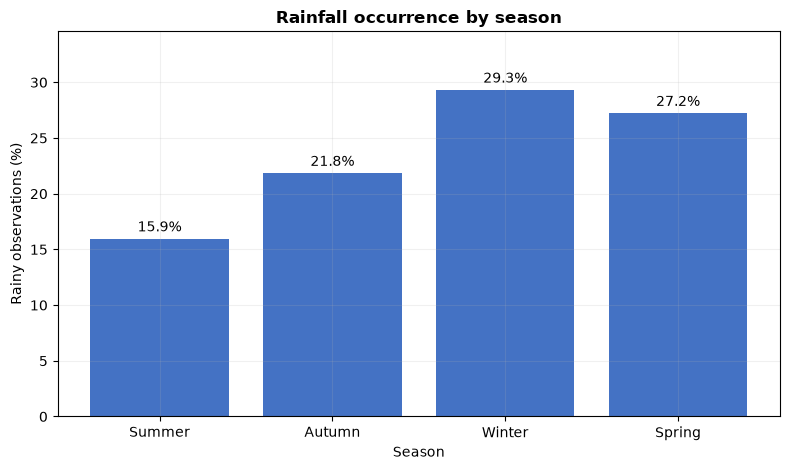

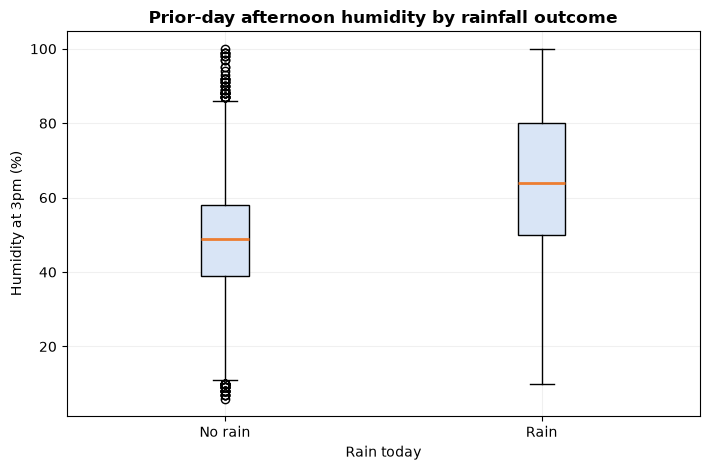

In [7]:
def date_to_season(date):
    if date.month in (12, 1, 2): return "Summer"
    if date.month in (3, 4, 5): return "Autumn"
    if date.month in (6, 7, 8): return "Winter"
    return "Spring"

df["Date"] = pd.to_datetime(df["Date"], errors="raise")
df["Season"] = df["Date"].apply(date_to_season)
df = df.drop(columns="Date")

season_order = ["Summer", "Autumn", "Winter", "Spring"]
seasonal = (df.assign(RainFlag=(df["RainToday"] == "Yes").astype(int))
              .groupby("Season", observed=False)["RainFlag"].agg(["mean", "count"])
              .reindex(season_order))
fig, ax = plt.subplots(figsize=(8, 4.8))
bars = ax.bar(seasonal.index, seasonal["mean"] * 100, color="#4472C4")
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in seasonal["mean"] * 100], padding=3)
ax.set(title="Rainfall occurrence by season", xlabel="Season", ylabel="Rainy observations (%)")
ax.set_ylim(0, (seasonal["mean"] * 100).max() * 1.18)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "seasonal_rainfall.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7.2, 4.8))
humidity_groups = [df.loc[df["RainToday"] == label, "Humidity3pm"] for label in ["No", "Yes"]]
ax.boxplot(humidity_groups, tick_labels=["No rain", "Rain"], patch_artist=True,
           boxprops={"facecolor": "#D9E5F6"}, medianprops={"color": "#ED7D31", "linewidth": 2})
ax.set(title="Prior-day afternoon humidity by rainfall outcome", xlabel="Rain today", ylabel="Humidity at 3pm (%)")
fig.tight_layout()
plt.show()

## 10. Preprocessing

In [8]:
X = df.drop(columns="RainToday")
y = df["RainToday"]
assert "RainToday" not in X.columns and "RainTomorrow" not in X.columns

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "category", "string"]).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([("scaler", StandardScaler())]), numeric_features),
    ("cat", Pipeline([("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
])
print(f"Train rows: {len(X_train):,}; test rows: {len(X_test):,}")
print(f"Numeric features: {len(numeric_features)}; categorical features: {len(categorical_features)}")

Train rows: 6,045; test rows: 1,512
Numeric features: 16; categorical features: 6


## 11. Train/Test Split

In [9]:
split_check = pd.DataFrame({
    "Full": y.value_counts(normalize=True),
    "Train": y_train.value_counts(normalize=True),
    "Test": y_test.value_counts(normalize=True),
})
display(split_check.round(3))

,Full,Train,Test
RainToday,,,
No,0.763,0.763,0.763
Yes,0.237,0.237,0.237


## 12. Baseline Model

In [10]:
def evaluate_model(name, model):
    prediction = model.predict(X_test)
    classes = list(model.classes_ if hasattr(model, "classes_") else model.named_steps["classifier"].classes_)
    probability = model.predict_proba(X_test)[:, classes.index("Yes")]
    return {"Model": name,
            "Accuracy": accuracy_score(y_test, prediction),
            "Precision": precision_score(y_test, prediction, pos_label="Yes", zero_division=0),
            "Recall": recall_score(y_test, prediction, pos_label="Yes", zero_division=0),
            "F1": f1_score(y_test, prediction, pos_label="Yes", zero_division=0),
            "ROC-AUC": roc_auc_score((y_test == "Yes").astype(int), probability)}

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_metrics = evaluate_model("Majority-class baseline", dummy)
pd.DataFrame([dummy_metrics]).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Majority-class baseline,0.763,0.0,0.0,0.0,0.5


## 13. Logistic Regression

In [11]:
def make_pipeline(classifier):
    return Pipeline([("preprocessor", preprocessor), ("classifier", classifier)])

logistic_baseline = make_pipeline(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
logistic_baseline.fit(X_train, y_train)
logistic_baseline_metrics = evaluate_model("Logistic Regression (baseline)", logistic_baseline)
pd.DataFrame([logistic_baseline_metrics]).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression (baseline),0.831,0.692,0.514,0.59,0.851


## 14. Random Forest

In [12]:
forest_baseline = make_pipeline(
    RandomForestClassifier(n_estimators=150, random_state=RANDOM_STATE, n_jobs=1))
forest_baseline.fit(X_train, y_train)
forest_baseline_metrics = evaluate_model("Random Forest (baseline)", forest_baseline)
pd.DataFrame([forest_baseline_metrics]).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest (baseline),0.849,0.763,0.522,0.62,0.889


## 15. Hyperparameter Tuning

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

logistic_search = GridSearchCV(
    make_pipeline(LogisticRegression(max_iter=3000, solver="saga", random_state=RANDOM_STATE)),
    {"classifier__C": [0.1, 1.0],
     "classifier__l1_ratio": [0.0, 1.0],
     "classifier__class_weight": [None, "balanced"]},
    scoring="roc_auc", cv=cv, n_jobs=1, refit=True)
logistic_search.fit(X_train, y_train)

forest_search = GridSearchCV(
    make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)),
    {"classifier__n_estimators": [150],
     "classifier__max_depth": [None, 10],
     "classifier__min_samples_split": [2, 5],
     "classifier__class_weight": [None, "balanced_subsample"]},
    scoring="roc_auc", cv=cv, n_jobs=1, refit=True)
forest_search.fit(X_train, y_train)

print("Logistic best parameters:", logistic_search.best_params_)
print(f"Logistic best CV ROC-AUC: {logistic_search.best_score_:.4f}")
print("Forest best parameters:", forest_search.best_params_)
print(f"Forest best CV ROC-AUC: {forest_search.best_score_:.4f}")

Logistic best parameters: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced', 'classifier__l1_ratio': 0.0}
Logistic best CV ROC-AUC: 0.8715
Forest best parameters: {'classifier__class_weight': 'balanced_subsample', 'classifier__max_depth': None, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 150}
Forest best CV ROC-AUC: 0.8969


## 16. Model Evaluation

Accuracy measures all correct decisions, but the minority rain class makes precision, recall, and F1 essential. Recall quantifies the share of rainy days detected; precision quantifies how often a rain prediction is correct; F1 balances the two. ROC-AUC evaluates ranking quality across thresholds.

In [14]:
models = {
    "Majority-class baseline": dummy,
    "Logistic Regression (baseline)": logistic_baseline,
    "Random Forest (baseline)": forest_baseline,
    "Logistic Regression (tuned)": logistic_search.best_estimator_,
    "Random Forest (tuned)": forest_search.best_estimator_,
}
comparison = pd.DataFrame([evaluate_model(name, model) for name, model in models.items()])
display(comparison.round(3))

final_name = ("Random Forest (tuned)"
              if forest_search.best_score_ >= logistic_search.best_score_
              else "Logistic Regression (tuned)")
final_model = models[final_name]
final_prediction = final_model.predict(X_test)
final_classes = list(final_model.named_steps["classifier"].classes_)
final_probability = final_model.predict_proba(X_test)[:, final_classes.index("Yes")]
print("Selected model:", final_name)
print(classification_report(y_test, final_prediction, zero_division=0))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Majority-class baseline,0.763,0.000,0.000,0.000,0.500
1,Logistic Regression (baseline),0.831,0.692,0.514,0.590,0.851
2,Random Forest (baseline),0.849,0.763,0.522,0.620,0.889
3,Logistic Regression (tuned),0.775,0.517,0.746,0.611,0.851
4,Random Forest (tuned),0.841,0.752,0.492,0.595,0.885


Selected model: Random Forest (tuned)
              precision    recall  f1-score   support

          No       0.86      0.95      0.90      1154
         Yes       0.75      0.49      0.59       358

    accuracy                           0.84      1512
   macro avg       0.80      0.72      0.75      1512
weighted avg       0.83      0.84      0.83      1512



## 17. Model Comparison

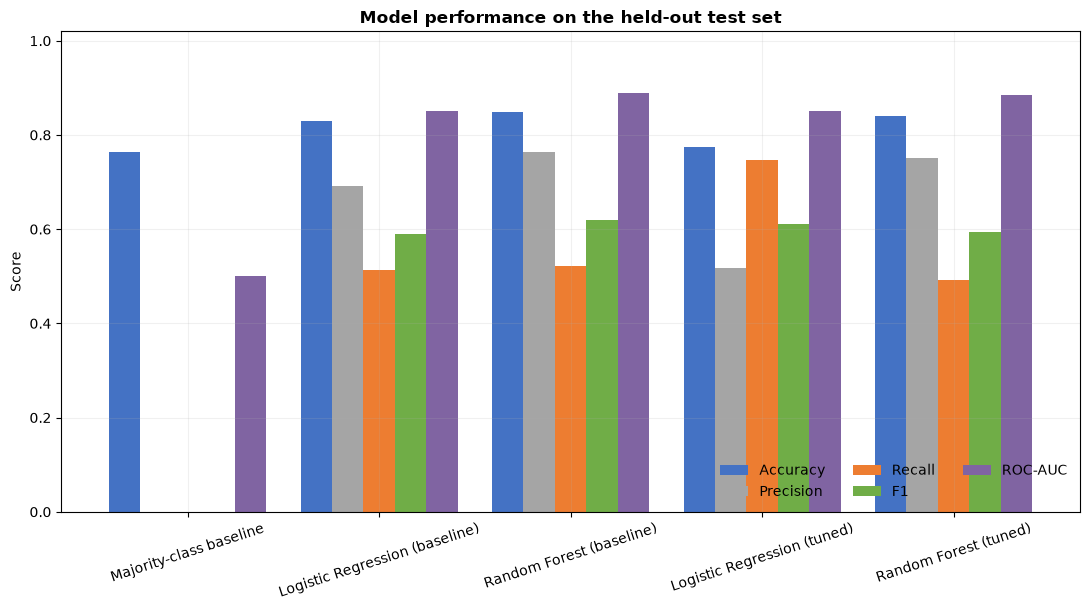

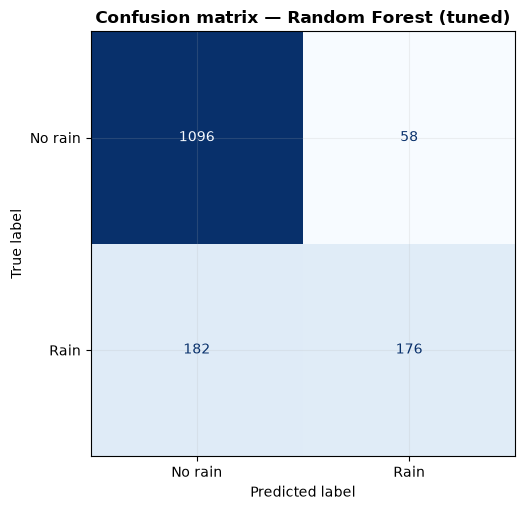

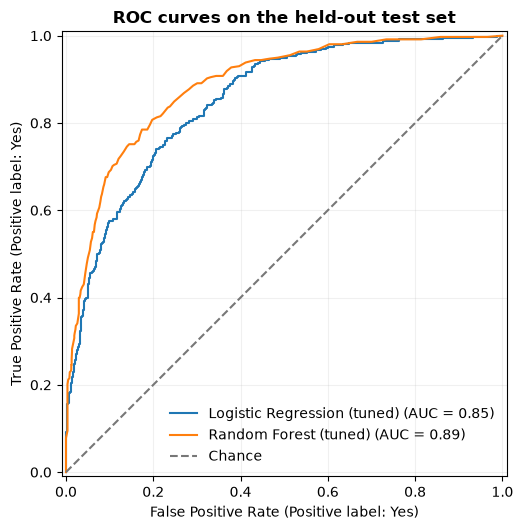

In [15]:
metric_columns = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
fig, ax = plt.subplots(figsize=(11, 6.2))
comparison.set_index("Model")[metric_columns].plot(
    kind="bar", ax=ax, width=0.82,
    color=["#4472C4", "#A5A5A5", "#ED7D31", "#70AD47", "#8064A2"])
ax.set(title="Model performance on the held-out test set", xlabel="", ylabel="Score", ylim=(0, 1.02))
ax.legend(loc="lower right", ncol=3, frameon=False)
ax.tick_params(axis="x", rotation=18)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "model_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(6.2, 5.2))
ConfusionMatrixDisplay.from_predictions(y_test, final_prediction, labels=["No", "Yes"],
    display_labels=["No rain", "Rain"], cmap="Blues", colorbar=False, ax=ax)
ax.set_title(f"Confusion matrix — {final_name}")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "confusion_matrix.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 5.4))
for name in ["Logistic Regression (tuned)", "Random Forest (tuned)"]:
    RocCurveDisplay.from_estimator(models[name], X_test, y_test, pos_label="Yes", name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", color="#777777", label="Chance")
ax.set_title("ROC curves on the held-out test set")
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "roc_curve.png", dpi=180, bbox_inches="tight")
plt.show()

## 18. Feature Interpretation

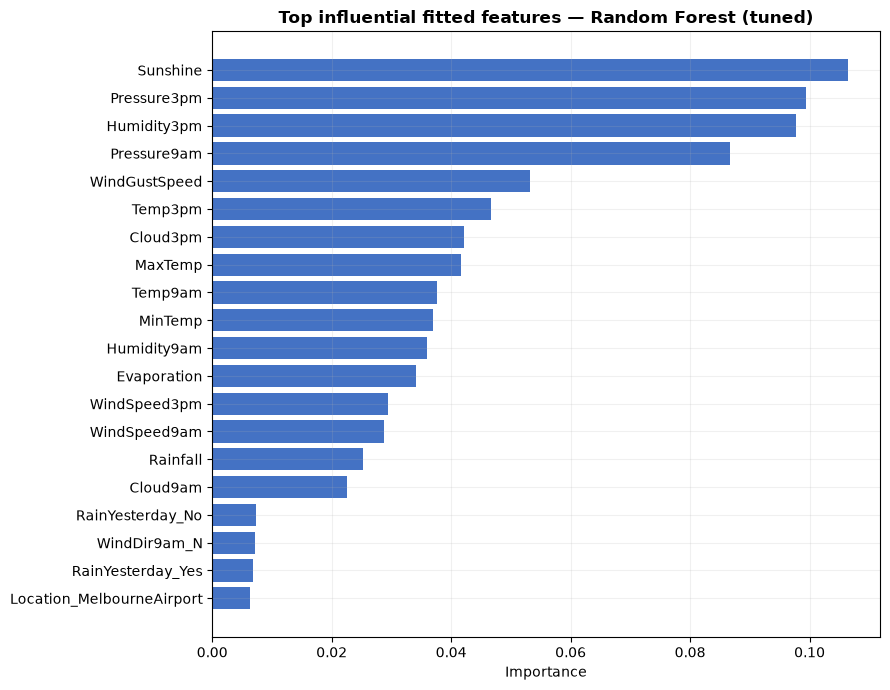

These features were influential for the fitted model; the ranking does not establish causality.


In [16]:
feature_names = final_model.named_steps["preprocessor"].get_feature_names_out()
classifier = final_model.named_steps["classifier"]
if hasattr(classifier, "feature_importances_"):
    values, value_label = classifier.feature_importances_, "Importance"
else:
    values, value_label = np.abs(classifier.coef_[0]), "Absolute coefficient"
importance = pd.DataFrame({"Feature": feature_names, value_label: values}).nlargest(20, value_label).sort_values(value_label)
importance["Feature"] = importance["Feature"].str.replace(r"^(num|cat)__", "", regex=True)
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(importance["Feature"], importance[value_label], color="#4472C4")
ax.set(title=f"Top influential fitted features — {final_name}", xlabel=value_label, ylabel="")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "feature_importance.png", dpi=180, bbox_inches="tight")
plt.show()
print("These features were influential for the fitted model; the ranking does not establish causality.")

## 19. Final Model

In [17]:
model_path = MODELS_DIR / "rainfall_classifier.joblib"
joblib.dump(final_model, model_path)
reloaded_model = joblib.load(model_path)
assert np.array_equal(reloaded_model.predict(X_test.iloc[:5]), final_model.predict(X_test.iloc[:5]))
print(f"Saved and reload-tested: {model_path}")

Saved and reload-tested: models\rainfall_classifier.joblib


## 20. Example Prediction

In [18]:
sample = X_test.iloc[[0]]
sample_index = sample.index[0]
sample_prediction = reloaded_model.predict(sample)[0]
sample_classes = list(reloaded_model.named_steps["classifier"].classes_)
sample_probability = reloaded_model.predict_proba(sample)[0, sample_classes.index("Yes")]
pd.DataFrame({"True class": [y_test.loc[sample_index]],
              "Predicted class": [sample_prediction],
              "Rain probability": [sample_probability]}, index=[sample_index])

,True class,Predicted class,Rain probability
66788,No,No,0.34


## 21. Limitations

- Complete-case filtering discards many rows and can bias the retained sample.
- The scope is limited to three nearby Melbourne-area stations.
- A random stratified split supports the IBM exercise but can overstate deployment performance when nearby dates are correlated; time-aware validation is a valuable next step.
- Feature influence is predictive, not causal.
- Weather and climate patterns may shift beyond the 2007–2017 observation period.

## 22. Conclusion

The selected **Random Forest (tuned)** achieved **0.841 accuracy**, **0.752 precision**, **0.492 recall**, **0.595 F1**, and **0.885 ROC-AUC** on the held-out test set. The complete fitted preprocessing-and-classifier pipeline is saved to `models/rainfall_classifier.joblib`.

### Executed model comparison

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Majority-class baseline | 0.763 | 0.000 | 0.000 | 0.000 | 0.500 |
| Logistic Regression (baseline) | 0.831 | 0.692 | 0.514 | 0.590 | 0.851 |
| Random Forest (baseline) | 0.849 | 0.763 | 0.522 | 0.620 | 0.889 |
| Logistic Regression (tuned) | 0.775 | 0.517 | 0.746 | 0.611 | 0.851 |
| Random Forest (tuned) | 0.841 | 0.752 | 0.492 | 0.595 | 0.885 |